# Polymarket historical-wallet EDA
This notebook analyzes **all 55,952 rows** of the professor’s wallet_features.csv, without sampling or removing high-activity wallets. Each row is a wallet summary, not a trade.

## 1. Understand the coverage
The course insider_demo notebook says the cohort includes buyers in five event groups between **April 2025 and March 2026**. Features summarize their whole observed history in the lab files. The source describes 1,644 markets and 8.4M trade rows underlying the feature construction; these are source documentation counts, not raw records reanalyzed here.

This is the full supplied wallet table, **not all Polymarket activity**. The CSV has no trade timestamps, so exact historical start/end dates and daily trends cannot be calculated. BUY/SELL percentages and per-trade duplicate rates also cannot be recovered from wallet summaries.

A compressed copy of the course CSV is embedded below so this runs in Colab without a password or local path. Wallet IDs are pseudonymous.

In [ ]:
import base64, gzip, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path
OUTPUT = Path("historical_eda_outputs")
OUTPUT.mkdir(exist_ok=True)
CSV_GZIP_BASE64 = '...'
df = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(CSV_GZIP_BASE64))))
print(f"Loaded {len(df):,} wallets and {len(df.columns)} columns.")
display(df.head())

Loaded 55,952 wallets and 11 columns.


,wallet,trade_count,unique_markets,total_notional,avg_buy_price,concentration,max_single_buy,market_notional_ratio,wallet_age_days,position_anomaly_ratio,confirmed
0,w_b6640fc6a7,6,1,241.805798,0.576023,1.000000,88.3200,0.000322,1.598889,0.365252,False
1,w_ce85723407,6,4,33.230088,0.936964,0.405506,12.4750,0.000362,49.930856,1.501651,False
2,w_b92e826e83,7,4,43.640110,0.340639,0.483274,12.0000,0.000021,17.895579,1.099906,False
3,w_ab04538147,10,6,135.093199,0.204462,0.388621,52.5000,0.000559,19.121771,2.331724,False
4,w_09a7eb8ca6,13,13,64.902260,0.678542,0.077591,5.0358,0.000114,4.868113,1.008677,False


## 2. Audit the data without silently deleting rows
Check missing values, repeated wallet IDs, non-finite numbers, negative numeric values, and proportions outside 0–1. These are basic validity checks, not proof that the source is error-free. Keep every row for this EDA.

In [ ]:
numeric = df.select_dtypes(include="number")
proportions = ["avg_buy_price", "concentration", "market_notional_ratio"]
audit = pd.Series({"rows": len(df), "missing_cells": int(df.isna().sum().sum()), "duplicate_wallet_ids": int(df.wallet.duplicated().sum()), "nonfinite_numeric_cells": int((~np.isfinite(numeric)).sum().sum()), "negative_numeric_cells": int((numeric < 0).sum().sum()), "out_of_range_proportions": int(((df[proportions] < 0) | (df[proportions] > 1)).sum().sum())})
display(audit.to_frame("count"))
audit.to_csv(OUTPUT / "quality_audit.csv")

,count
rows,55952
missing_cells,0
duplicate_wallet_ids,0
nonfinite_numeric_cells,0
negative_numeric_cells,0
out_of_range_proportions,0


## 3. Summarize typical wallets and extreme values
The median is the middle wallet. The mean can be pulled upward by a few very large wallets. Total notional is the course spending measure; it is not profit. Observed history length means time from first to last recorded trade, not account age.

In [ ]:
cols = ["total_notional", "trade_count", "unique_markets", "concentration", "wallet_age_days"]
summary = df[cols].describe(percentiles=[.5,.9,.99]).T
display(summary)
summary.to_csv(OUTPUT / "summary.csv")
n_top = int(np.ceil(.01 * len(df)))
top_share = df.total_notional.nlargest(n_top).sum() / df.total_notional.sum() * 100
print(f"Top {n_top:,} wallets (~1%) account for {top_share:.1f}% of this cohort's spending.")
print(f"Median spending: ${df.total_notional.median():,.0f}; mean: ${df.total_notional.mean():,.0f}")
print(f"Median trades: {df.trade_count.median():.0f}; median markets: {df.unique_markets.median():.0f}")
print(f"Median concentration: {df.concentration.median():.1%}; median observed span: {df.wallet_age_days.median():.1f} days")

,count,mean,std,min,50%,90%,99%,max
total_notional,55952.0,10481.786812,163481.228852,0.011400,197.841175,5581.980664,147210.337396,1.971762e+07
trade_count,55952.0,74.888243,765.536114,3.000000,10.000000,71.000000,1053.000000,5.988500e+04
unique_markets,55952.0,9.041464,23.006774,1.000000,4.000000,17.000000,87.000000,1.177000e+03
concentration,55952.0,0.560874,0.255401,0.008329,0.526763,0.970916,1.000000,1.000000e+00
wallet_age_days,55952.0,47.750300,69.911205,0.000000,20.841204,147.381231,292.057479,3.626167e+02


Top 560 wallets (~1%) account for 72.4% of this cohort's spending.
Median spending: $198; mean: $10,482
Median trades: 10; median markets: 4
Median concentration: 52.7%; median observed span: 20.8 days


## 4. Visualize spending and activity
The spending histogram uses a logarithmic horizontal axis: each labeled step is a tenfold increase. This lets us see small and very large wallets on one graph. The vertical lines compare the typical wallet with the average.

Additional charts describe trading frequency, market count, and observed history length. These are distributions of wallet summaries, not changes over calendar time.

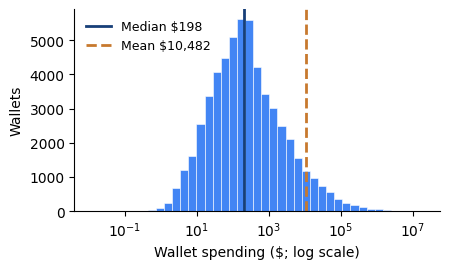

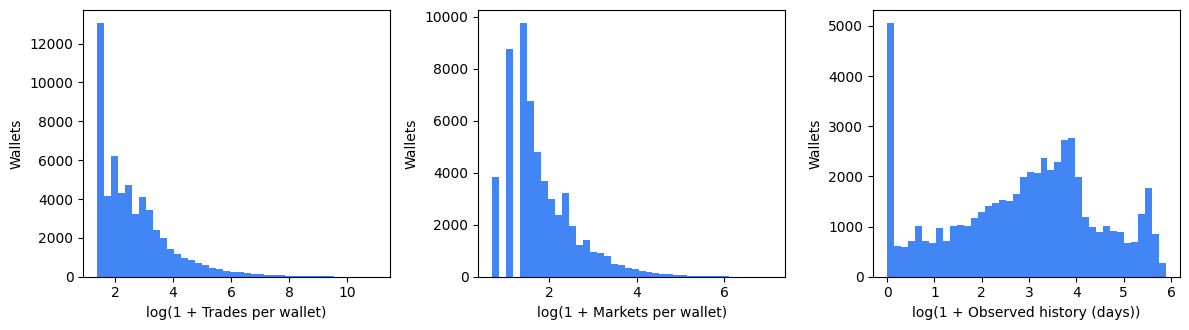

In [ ]:
fig, ax = plt.subplots(figsize=(4.6,2.8))
v = df.total_notional
ax.hist(v, bins=np.geomspace(v.min(), v.max(), 42), color="#4285F4", edgecolor="white", linewidth=.4)
ax.set_xscale("log")
ax.axvline(v.median(), color="#173F78", linewidth=2, label=f"Median ${v.median():,.0f}")
ax.axvline(v.mean(), color="#C7792E", linewidth=2, linestyle="--", label=f"Mean ${v.mean():,.0f}")
ax.set_xlabel("Wallet spending ($; log scale)"); ax.set_ylabel("Wallets")
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(OUTPUT / "spending_distribution.png", dpi=240); plt.show()
fig, axes = plt.subplots(1,3,figsize=(12,3.4))
for ax, col, label in zip(axes, ["trade_count","unique_markets","wallet_age_days"], ["Trades per wallet","Markets per wallet","Observed history (days)"]):
    ax.hist(np.log1p(df[col]), bins=40, color="#4285F4")
    ax.set_xlabel("log(1 + " + label + ")"); ax.set_ylabel("Wallets")
fig.tight_layout(); fig.savefig(OUTPUT / "activity_distributions.png", dpi=180); plt.show()

## 5. Findings for the presentation
- **Spending is highly uneven:** median about $198, mean about $10,482. A few very large wallets pull the mean upward.
- The top approximately 1% of wallets account for **72.4%** of recorded spending in this cohort.
- The typical wallet made **10 trades across 4 markets**.
- The median wallet put **52.7%** of its spending into its most-used market.
- Median observed history was **20.8 days**. Different wallets have different observation spans.
- No missing cells or repeated wallet IDs were found. This does not audit the underlying individual trades.

## 6. Connection to modeling
This EDA includes all wallets. The K-means analysis separately excludes wallets with 500+ markets OR 2,000+ trades, leaving 55,668. The skewed measurements motivate compressing large values and standardizing before distance-based modeling. Unusual behavior alone is not evidence of insider trading.

The 19 marked cases are known positives; all other wallets are not verified non-insiders. Do not report the marked fraction as the true rate of insider trading.

Source: professor’s student package dated 2026-10-07, notebooks/data/wallet_features.csv and coverage description in notebooks/insider_demo.ipynb.